In [1]:
#Cau1
import torch 
print('PyTorch:', torch.__version__) 
print('CUDA available:', torch.cuda.is_available()) 
if torch.cuda.is_available(): 
    print('GPU:', torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


Tổng số lượng mẫu ảnh tìm thấy: 7627
Danh sách các lớp (Classes): ['0', '1', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '2', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '3', '30', '31', '32', '33', '34', '35', '36', '37', '38', '39', '4', '40', '41', '42', '43', '44', '45', '46', '47', '48', '49', '5', '50', '51', '6', '7', '8', '9']
 KIỂM TRA TENSOR BATCH (CÂU 2)
Shape của batch ảnh (B x C x H x W): torch.Size([4, 3, 48, 48])
Shape của batch nhãn: torch.Size([4])
Giá trị Min của tensor sau khi Normalize: -0.8824
Giá trị Max của tensor sau khi Normalize: 0.9137


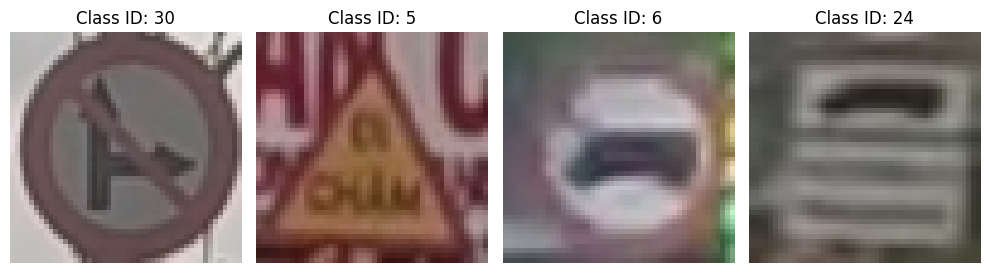

✓ Đã load dữ liệu thành công từ ImageFolder, kiểm tra Tensor và hiển thị ảnh hoàn tất!


In [2]:
#Cau2
import os
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

# ==========================================
# 1. THIẾT LẬP ĐƯỜNG DẪN VÀ TRANSFORMS
# ==========================================
# Đường dẫn chính xác trỏ đến thư mục chứa các thư mục con theo class (ví dụ thư mục '7')
data_dir = "/kaggle/input/datasets/thinhduong187/dataset/vnts_classification"

# Định nghĩa các phép biến đổi ảnh sang Tensor và chuẩn hóa về khoảng [-1, 1]
transform = transforms.Compose([
    transforms.Resize((48, 48)),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5)),
])

# Sử dụng ImageFolder để tự động gán nhãn dựa theo tên thư mục con (0, 1, 2, ..., 42)
dataset = datasets.ImageFolder(root=data_dir, transform=transform)

print(f"Tổng số lượng mẫu ảnh tìm thấy: {len(dataset)}")
print(f"Danh sách các lớp (Classes): {dataset.classes}")

# DataLoader nhóm các sample thành mini-batch
dataloader = DataLoader(
    dataset, batch_size=4, shuffle=True, num_workers=0, pin_memory=True
)

# ==========================================
# 2. LẤY MỘT BATCH VÀ KIỂM TRA SHAPE, MIN/MAX
# ==========================================
images, labels = next(iter(dataloader))

print("=" * 50)
print(" KIỂM TRA TENSOR BATCH (CÂU 2)")
print("=" * 50)
print(f"Shape của batch ảnh (B x C x H x W): {images.shape}")
print(f"Shape của batch nhãn: {labels.shape}")
print(f"Giá trị Min của tensor sau khi Normalize: {images.min().item():.4f}")
print(f"Giá trị Max của tensor sau khi Normalize: {images.max().item():.4f}")
print("=" * 50)


# ==========================================
# 3. HÀM DENORMALIZE VÀ HIỂN THỊ ẢNH
# ==========================================
def denormalize(tensor, mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5)):
  """Hàm chuyển ngược tensor từ khoảng [-1, 1] về [0, 1] để hiển thị ảnh."""
  denorm_tensor = tensor.clone()
  for t, m, s in zip(denorm_tensor, mean, std):
    t.mul_(s).add_(m)
  return torch.clamp(denorm_tensor, 0, 1)


# Hiển thị 4 ảnh đầu tiên trong batch
plt.figure(figsize=(10, 5))
for i in range(len(images)):
  plt.subplot(1, len(images), i + 1)
  img_denorm = denormalize(images[i])
  img_np = img_denorm.permute(1, 2, 0).numpy()

  plt.imshow(img_np)
  plt.title(f"Class ID: {labels[i].item()}")
  plt.axis("off")

plt.tight_layout()
plt.show()
print(
    "✓ Đã load dữ liệu thành công từ ImageFolder, kiểm tra Tensor và hiển thị"
    " ảnh hoàn tất!"
)

In [3]:
#Cau3
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

# ==========================================
# 1. ĐỊNH NGHĨA KIẾN TRÚC TinyTrafficCNN
# ==========================================


class TinyTrafficCNN(nn.Module):

  def __init__(self, num_classes):
    super().__init__()
    self.block1 = nn.Sequential(
        nn.Conv2d(3, 16, kernel_size=3, padding=1),
        nn.BatchNorm2d(16),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2),
    )
    self.block2 = nn.Sequential(
        nn.Conv2d(16, 32, kernel_size=3, padding=1),
        nn.BatchNorm2d(32),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2),
    )
    self.block3 = nn.Sequential(
        nn.Conv2d(32, 64, kernel_size=3, padding=1),
        nn.BatchNorm2d(64),
        nn.ReLU(),
    )
    self.pool = nn.AdaptiveAvgPool2d((1, 1))
    self.dropout = nn.Dropout(0.5)
    self.fc = nn.Linear(64, num_classes)

  def forward(self, x):
    x = self.block1(x)
    x = self.block2(x)
    x = self.block3(x)
    x = self.pool(x)
    x = torch.flatten(x, 1)
    x = self.dropout(x)
    x = self.fc(x)
    return x


# ==========================================
# 2. KIỂM TRA THIẾT BỊ VÀ LOAD DATASET
# ==========================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"-> Đang sử dụng thiết bị: {device}")

data_dir = "/kaggle/input/datasets/thinhduong187/dataset/vnts_classification"
transform = transforms.Compose([
    transforms.Resize((48, 48)),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5)),
])

print("-> Đang tải dataset từ ImageFolder...")
dataset = datasets.ImageFolder(root=data_dir, transform=transform)
num_classes = len(dataset.classes)
print(
    f"-> Tải thành công! Tổng số mẫu: {len(dataset)}, Số lượng lớp:"
    f" {num_classes}"
)

# Khởi tạo mô hình
model = TinyTrafficCNN(num_classes=num_classes).to(device)
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"-> Tổng số tham số (Parameters): {total_params:,}")

# Chia tập Train / Val (Dùng num_workers=0 để tránh treo cell trên Kaggle)
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
train_dataset, val_dataset = random_split(
    dataset, [train_size, val_size], generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(
    train_dataset, batch_size=64, shuffle=True, num_workers=0
)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False, num_workers=0)

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=0.001)

# ==========================================
# 3. HUẤN LUYỆN THỬ NGHIỆM (2 EPOCHS)
# ==========================================
num_epochs = 2
print(
    "\n=== BẮT ĐẦU VÒNG LẶP HUẤN LUYỆN (TRAINING LOOP) ==="
)  # In thông báo để thấy ngay

for epoch in range(num_epochs):
  model.train()
  running_loss = 0.0
  correct = 0
  total = 0

  print(f"Epoch {epoch+1}/{num_epochs} đang chạy...")
  for batch_idx, (images, labels) in enumerate(train_loader):
    images, labels = images.to(device), labels.to(device)

    optimizer.zero_grad(set_to_none=True)
    outputs = model(images)
    loss = criterion(outputs, labels)
    loss.backward()
    optimizer.step()

    running_loss += loss.item() * images.size(0)
    _, predicted = outputs.max(1)
    total += labels.size(0)
    correct += predicted.eq(labels).sum().item()

    # In tiến độ nhỏ mỗi 20 batch để biết code đang chạy
    if (batch_idx + 1) % 20 == 0:
      print(
          f"  - Đã xử lý xong batch {batch_idx+1}/{len(train_loader)}..."
          f" (Loss: {loss.item():.4f})"
      )

  train_loss = running_loss / total
  train_acc = 100.0 * correct / total

  # Validation Phase
  model.eval()
  val_loss = 0.0
  val_correct = 0
  val_total = 0

  with torch.inference_mode():
    for images, labels in val_loader:
      images, labels = images.to(device), labels.to(device)
      outputs = model(images)
      loss = criterion(outputs, labels)

      val_loss += loss.item() * images.size(0)
      _, predicted = outputs.max(1)
      val_total += labels.size(0)
      val_correct += predicted.eq(labels).sum().item()

  val_loss = val_loss / val_total
  val_acc = 100.0 * val_correct / val_total

  print(
      f"--> KẾT QUẢ EPOCH [{epoch+1}/{num_epochs}] | Train Loss: {train_loss:.4f}"
      f" | Train Acc: {train_acc:.2f}% | Val Loss: {val_loss:.4f} | Val Acc:"
      f" {val_acc:.2f}%\n"
  )

print("✓ Hoàn thành thí nghiệm huấn luyện baseline thành công!")

-> Đang sử dụng thiết bị: cuda
-> Đang tải dataset từ ImageFolder...
-> Tải thành công! Tổng số mẫu: 7627, Số lượng lớp: 52
-> Tổng số tham số (Parameters): 27,188

=== BẮT ĐẦU VÒNG LẶP HUẤN LUYỆN (TRAINING LOOP) ===
Epoch 1/2 đang chạy...
  - Đã xử lý xong batch 20/96... (Loss: 3.4388)
  - Đã xử lý xong batch 40/96... (Loss: 3.0888)
  - Đã xử lý xong batch 60/96... (Loss: 2.8040)
  - Đã xử lý xong batch 80/96... (Loss: 2.7773)
--> KẾT QUẢ EPOCH [1/2] | Train Loss: 3.0895 | Train Acc: 21.78% | Val Loss: 2.4585 | Val Acc: 36.76%

Epoch 2/2 đang chạy...
  - Đã xử lý xong batch 20/96... (Loss: 2.3636)
  - Đã xử lý xong batch 40/96... (Loss: 2.3944)
  - Đã xử lý xong batch 60/96... (Loss: 2.4075)
  - Đã xử lý xong batch 80/96... (Loss: 2.4160)
--> KẾT QUẢ EPOCH [2/2] | Train Loss: 2.3846 | Train Acc: 35.63% | Val Loss: 2.0219 | Val Acc: 48.36%

✓ Hoàn thành thí nghiệm huấn luyện baseline thành công!


In [4]:
#Cau4
import json
import os
import time
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from sklearn.metrics import accuracy_score, f1_score

# ==========================================
# 0. KHỞI TẠO THƯ MỤC OUTPUTS THEO ĐÚNG CẤU TRÚC LAB
# ==========================================
os.makedirs("outputs/vnts_tiny/models", exist_ok=True)
os.makedirs("outputs/vnts_tiny/figures", exist_ok=True)
os.makedirs("outputs/vnts_tiny/benchmark", exist_ok=True)

# Thiết bị huấn luyện
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"-> Thiết bị sử dụng: {device}")

# ==========================================
# 1. ĐỊNH NGHĨA MODEL TinyTrafficCNN
# ==========================================


class TinyTrafficCNN(nn.Module):

  def __init__(self, num_classes):
    super().__init__()
    self.block1 = nn.Sequential(
        nn.Conv2d(3, 16, kernel_size=3, padding=1),
        nn.BatchNorm2d(16),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2),
    )
    self.block2 = nn.Sequential(
        nn.Conv2d(16, 32, kernel_size=3, padding=1),
        nn.BatchNorm2d(32),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2),
    )
    self.block3 = nn.Sequential(
        nn.Conv2d(32, 64, kernel_size=3, padding=1),
        nn.BatchNorm2d(64),
        nn.ReLU(),
    )
    self.pool = nn.AdaptiveAvgPool2d((1, 1))
    self.dropout = nn.Dropout(0.5)
    self.fc = nn.Linear(64, num_classes)

  def forward(self, x):
    x = self.block1(x)
    x = self.block2(x)
    x = self.block3(x)
    x = self.pool(x)
    x = torch.flatten(x, 1)
    x = self.dropout(x)
    x = self.fc(x)
    return x


# ==========================================
# 2. CHUẨN BỊ DỮ LIỆU & DATALOADER
# ==========================================
data_dir = "/kaggle/input/datasets/thinhduong187/dataset/vnts_classification"

# Transform chuẩn theo Mục 2.4.5
transform = transforms.Compose([
    transforms.Resize((48, 48)),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5)),
])

dataset = datasets.ImageFolder(root=data_dir, transform=transform)
num_classes = len(dataset.classes)

# Chia Train / Val (80% / 20%) cố định seed
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
train_dataset, val_dataset = random_split(
    dataset, [train_size, val_size], generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(
    train_dataset, batch_size=64, shuffle=True, num_workers=0
)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False, num_workers=0)

# ==========================================
# 3. KHỞI TẠO MÔ HÌNH, LOSS VÀ OPTIMIZER
# ==========================================
model = TinyTrafficCNN(num_classes=num_classes).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=0.001)

num_epochs = 10  # Có thể tăng số epoch để đánh giá overfitting
history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": [],
    "val_f1": [],
}
best_val_acc = 0.0
start_time_total = time.time()

print("\n=== BẮT ĐẦU HUẤN LUYỆN BASELINE (CÂU 4) ===")

for epoch in range(num_epochs):
  epoch_start_time = time.time()

  # --- Training Phase ---
  model.train()
  running_loss = 0.0
  train_preds, train_targets = [], []

  for images, labels in train_loader:
    images, labels = images.to(device), labels.to(device)

    optimizer.zero_grad(set_to_none=True)
    outputs = model(images)
    loss = criterion(outputs, labels)
    loss.backward()
    optimizer.step()

    running_loss += loss.item() * images.size(0)
    _, preds = outputs.max(1)
    train_preds.extend(preds.cpu().numpy())
    train_targets.extend(labels.cpu().numpy())

  epoch_train_loss = running_loss / len(train_dataset)
  epoch_train_acc = accuracy_score(train_targets, train_preds) * 100

  # --- Validation Phase ---
  model.eval()
  val_loss = 0.0
  val_preds, val_targets = [], []

  with torch.inference_mode():
    for images, labels in val_loader:
      images, labels = images.to(device), labels.to(device)
      outputs = model(images)
      loss = criterion(outputs, labels)

      val_loss += loss.item() * images.size(0)
      _, preds = outputs.max(1)
      val_preds.extend(preds.cpu().numpy())
      val_targets.extend(labels.cpu().numpy())

  epoch_val_loss = val_loss / len(val_dataset)
  epoch_val_acc = accuracy_score(val_targets, val_preds) * 100
  epoch_val_f1 = (
      f1_score(val_targets, val_preds, average="macro", zero_division=0) * 100
  )
  epoch_time = time.time() - epoch_start_time

  # Lưu lịch sử
  history["train_loss"].append(epoch_train_loss)
  history["train_acc"].append(epoch_train_acc)
  history["val_loss"].append(epoch_val_loss)
  history["val_acc"].append(epoch_val_acc)
  history["val_f1"].append(epoch_val_f1)

  print(
      f"Epoch [{epoch+1}/{num_epochs}] ({epoch_time:.2f}s) | "
      f"Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.2f}% | "
      f"Val Loss: {epoch_val_loss:.4f} | Val Acc: {epoch_val_acc:.2f}% | Val"
      f" Macro-F1: {epoch_val_f1:.2f}%"
  )

  # --- Lưu Checkpoint tốt nhất (Theo Mục 2.4.19) ---
  if epoch_val_acc > best_val_acc:
    best_val_acc = epoch_val_acc
    # 1. Lưu state_dict
    torch.save(
        model.state_dir()
        if hasattr(model, "state_dir")
        else model.state_dict(),
        "outputs/vnts_tiny/models/best_state_dict.pth",
    )
    # 2. Lưu checkpoint đầy đủ
    checkpoint = {
        "epoch": epoch + 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "best_val_acc": best_val_acc,
    }
    torch.save(
        checkpoint, "outputs/vnts_tiny/models/best_checkpoint.pth"
    )
    # Lưu lại dự đoán tốt nhất để vẽ Confusion Matrix sau
    best_val_preds = val_preds
    best_val_targets = val_targets

total_training_time = time.time() - start_time_total
print(
    f"\n✓ Huấn luyện hoàn tất! Thời gian tổng cộng: {total_training_time:.2f}s."
    f" Accuracy cao nhất: {best_val_acc:.2f}%"
)

# ==========================================
# 4. LƯU CÁC ARTIFACT & VẼ BIỂU ĐỒ (MỤC 2.4.19 & 2.5.1)
# ==========================================

# A. Lưu model_info.json
model_info = {
    "architecture": "TinyTrafficCNN",
    "num_classes": num_classes,
    "input_size": [3, 48, 48],
    "normalization": {"mean": [0.5, 0.5, 0.5], "std": [0.5, 0.5, 0.5]},
    "classes": dataset.classes,
}
with open("outputs/vnts_tiny/models/model_info.json", "w") as f:
  json.dump(model_info, f, indent=4)

# B. Lưu run_summary.json
run_summary = {
    "platform": "Kaggle GPU" if torch.cuda.is_available() else "Kaggle CPU",
    "total_params": sum(p.numel() for p in model.parameters() if p.requires_grad),
    "total_training_time_sec": total_training_time,
    "best_val_accuracy": best_val_acc,
    "final_val_f1": history["val_f1"][-1],
}
with open("outputs/vnts_tiny/benchmark/kaggle_run_summary.json", "w") as f:
  json.dump(run_summary, f, indent=4)

# C. Vẽ và lưu Learning Curves (Loss & Accuracy)
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history["train_loss"], label="Train Loss")
plt.plot(history["val_loss"], label="Val Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training & Validation Loss")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history["train_acc"], label="Train Acc")
plt.plot(history["val_acc"], label="Val Acc")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training & Validation Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig("outputs/vnts_tiny/figures/training_history.png", dpi=300)
plt.close()

# ==========================================================
# 👇 BỔ SUNG ĐOẠN NÀY ĐỂ TẠO FILE training_history_f1.png 👇
# ==========================================================
plt.figure(figsize=(8, 5))
plt.plot(
    range(1, len(history["val_f1"]) + 1),
    history["val_f1"],
    label="Validation Macro-F1",
    color="orange",
    marker="o",
    linewidth=2,
)
plt.xlabel("Epoch")
plt.ylabel("Macro-F1 Score (%)")
plt.title("Training History - Validation Macro-F1 Score")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.7)
plt.tight_layout()
plt.savefig("outputs/vnts_tiny/figures/training_history_f1.png", dpi=300)
plt.close()
# ==========================================================

# D. Vẽ và lưu Confusion Matrix
plt.figure(figsize=(10, 8))
cm = confusion_matrix(best_val_targets, best_val_preds)
sns.heatmap(
    cm,
    annot=False,
    fmt="d",
    cmap="Blues",
    cbar=True,
    xticklabels=False,
    yticklabels=False,
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title(f"Confusion Matrix (Best Val Acc: {best_val_acc:.2f}%)")
plt.savefig("outputs/vnts_tiny/figures/confusion_matrix.png", dpi=300)
plt.close()

print(
    "✓ Đã lưu toàn bộ checkpoint, model_info, run_summary và các biểu đồ"
    " figures thành công!"
)

-> Thiết bị sử dụng: cuda

=== BẮT ĐẦU HUẤN LUYỆN BASELINE (CÂU 4) ===
Epoch [1/10] (9.96s) | Train Loss: 3.0650 | Train Acc: 23.09% | Val Loss: 2.4143 | Val Acc: 37.94% | Val Macro-F1: 10.07%
Epoch [2/10] (10.08s) | Train Loss: 2.3591 | Train Acc: 37.09% | Val Loss: 2.0061 | Val Acc: 50.92% | Val Macro-F1: 18.83%
Epoch [3/10] (10.05s) | Train Loss: 2.0625 | Train Acc: 43.88% | Val Loss: 1.7549 | Val Acc: 56.16% | Val Macro-F1: 21.77%
Epoch [4/10] (11.33s) | Train Loss: 1.8620 | Train Acc: 47.39% | Val Loss: 1.5723 | Val Acc: 55.96% | Val Macro-F1: 22.14%
Epoch [5/10] (11.36s) | Train Loss: 1.7335 | Train Acc: 49.30% | Val Loss: 1.4324 | Val Acc: 61.21% | Val Macro-F1: 26.99%
Epoch [6/10] (10.73s) | Train Loss: 1.6187 | Train Acc: 52.43% | Val Loss: 1.3188 | Val Acc: 65.14% | Val Macro-F1: 32.52%
Epoch [7/10] (11.28s) | Train Loss: 1.5310 | Train Acc: 53.94% | Val Loss: 1.2293 | Val Acc: 64.81% | Val Macro-F1: 32.06%
Epoch [8/10] (11.91s) | Train Loss: 1.4468 | Train Acc: 56.71% | Val 

In [5]:
#Cau5
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from sklearn.metrics import accuracy_score, f1_score
import time
import os

# Tạo thư mục output cho thí nghiệm Augmentation
os.makedirs("outputs/vnts_tiny_aug/models", exist_ok=True)
os.makedirs("outputs/vnts_tiny_aug/figures", exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
data_dir = "/kaggle/input/datasets/thinhduong187/dataset/vnts_classification"

# --- THAY ĐỔI CHÍNH: BẬT DATA AUGMENTATION MỨC NHẸ ---
transform_aug = transforms.Compose([
    transforms.Resize((48, 48)),
    transforms.RandomRotation(15),           # Xoay ngẫu nhiên góc nhỏ
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)), # Dịch chuyển nhẹ
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
])

dataset_aug = datasets.ImageFolder(root=data_dir, transform=transform_aug)
num_classes = len(dataset_aug.classes)

# Cố định seed chia tập dữ liệu để so sánh công bằng
train_size = int(0.8 * len(dataset_aug))
val_size = len(dataset_aug) - train_size
train_dataset, val_dataset = random_split(
    dataset_aug, [train_size, val_size], 
    generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False, num_workers=0)

# Định nghĩa lại mô hình TinyTrafficCNN
class TinyTrafficCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.block1 = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.block2 = nn.Sequential(
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.block3 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU()
        )
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.dropout = nn.Dropout(0.5)
        self.fc = nn.Linear(64, num_classes)

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.pool(x)
        x = torch.flatten(x, 1)
        x = self.dropout(x)
        x = self.fc(x)
        return x

model_aug = TinyTrafficCNN(num_classes=num_classes).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model_aug.parameters(), lr=0.001)

num_epochs = 10
best_val_acc_aug = 0.0

print("\n=== BẮT ĐẦU THÍ NGHIỆM ABLATION: TINYCNN + DATA AUGMENTATION ===")
for epoch in range(num_epochs):
    model_aug.train()
    running_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad(set_to_none=True)
        outputs = model_aug(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)

    train_loss = running_loss / len(train_dataset)

    # Validation
    model_aug.eval()
    val_preds, val_targets = [], []
    with torch.inference_mode():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model_aug(images)
            _, preds = outputs.max(1)
            val_preds.extend(preds.cpu().numpy())
            val_targets.extend(labels.cpu().numpy())

    val_acc = accuracy_score(val_targets, val_preds) * 100
    val_f1 = f1_score(val_targets, val_preds, average='macro', zero_division=0) * 100

    if val_acc > best_val_acc_aug:
        best_val_acc_aug = val_acc
        torch.save(model_aug.state_dict(), "outputs/vnts_tiny_aug/models/best_state_dict.pth")

    print(f"Epoch [{epoch+1}/{num_epochs}] | Train Loss: {train_loss:.4f} | Val Acc: {val_acc:.2f}% | Val Macro-F1: {val_f1:.2f}%")

print(f"\n✓ Hoàn thành thí nghiệm Augmentation! Accuracy cao nhất: {best_val_acc_aug:.2f}%")


=== BẮT ĐẦU THÍ NGHIỆM ABLATION: TINYCNN + DATA AUGMENTATION ===
Epoch [1/10] | Train Loss: 3.1572 | Val Acc: 31.45% | Val Macro-F1: 7.32%
Epoch [2/10] | Train Loss: 2.4463 | Val Acc: 45.81% | Val Macro-F1: 14.85%
Epoch [3/10] | Train Loss: 2.1571 | Val Acc: 51.25% | Val Macro-F1: 18.98%
Epoch [4/10] | Train Loss: 1.9570 | Val Acc: 52.23% | Val Macro-F1: 19.79%
Epoch [5/10] | Train Loss: 1.8415 | Val Acc: 53.80% | Val Macro-F1: 20.30%
Epoch [6/10] | Train Loss: 1.7149 | Val Acc: 59.11% | Val Macro-F1: 24.88%
Epoch [7/10] | Train Loss: 1.6232 | Val Acc: 57.67% | Val Macro-F1: 24.99%
Epoch [8/10] | Train Loss: 1.5344 | Val Acc: 60.75% | Val Macro-F1: 29.30%
Epoch [9/10] | Train Loss: 1.4904 | Val Acc: 61.34% | Val Macro-F1: 30.59%
Epoch [10/10] | Train Loss: 1.4479 | Val Acc: 64.68% | Val Macro-F1: 35.05%

✓ Hoàn thành thí nghiệm Augmentation! Accuracy cao nhất: 64.68%


In [6]:
#Cau6
import os
import matplotlib.pyplot as plt
import numpy as np
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

# ==========================================
# 1. THIẾT LẬP MÔI TRƯỜNG VÀ TẢI MODEL ĐÃ HUẤN LUYỆN
# ==========================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
data_dir = "/kaggle/input/datasets/thinhduong187/dataset/vnts_classification"

# Tạo thư mục lưu kết quả phân tích lỗi
os.makedirs("outputs/vnts_tiny/figures", exist_ok=True)

# Transform chuẩn
transform = transforms.Compose([
    transforms.Resize((48, 48)),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5)),
])

dataset = datasets.ImageFolder(root=data_dir, transform=transform)
num_classes = len(dataset.classes)

# Cố định lại đúng seed chia tập dữ liệu như lúc train
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
_, val_dataset = random_split(
    dataset, [train_size, val_size], generator=torch.Generator().manual_seed(42)
)

val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False, num_workers=0)


# Khai báo lại kiến trúc TinyTrafficCNN để load trọng số
import torch.nn as nn


class TinyTrafficCNN(nn.Module):

  def __init__(self, num_classes):
    super().__init__()
    self.block1 = nn.Sequential(
        nn.Conv2d(3, 16, kernel_size=3, padding=1),
        nn.BatchNorm2d(16),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2),
    )
    self.block2 = nn.Sequential(
        nn.Conv2d(16, 32, kernel_size=3, padding=1),
        nn.BatchNorm2d(32),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2),
    )
    self.block3 = nn.Sequential(
        nn.Conv2d(32, 64, kernel_size=3, padding=1),
        nn.BatchNorm2d(64),
        nn.ReLU(),
    )
    self.pool = nn.AdaptiveAvgPool2d((1, 1))
    self.dropout = nn.Dropout(0.5)
    self.fc = nn.Linear(64, num_classes)

  def forward(self, x):
    x = self.block1(x)
    x = self.block2(x)
    x = self.block3(x)
    x = self.pool(x)
    x = torch.flatten(x, 1)
    x = self.dropout(x)
    x = self.fc(x)
    return x


model = TinyTrafficCNN(num_classes=num_classes).to(device)
# Load lại trọng số tốt nhất đã lưu ở Câu 4
model.load_state_dict(
    torch.load(
        "outputs/vnts_tiny/models/best_state_dict.pth",
        weights_only=True,
        map_location=device,
    )
)
model.eval()

# ==========================================
# 2. HÀM DENORMALIZE ĐỂ HIỂN THỊ ẢNH
# ==========================================
def denormalize(tensor, mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5)):
  denorm_tensor = tensor.clone()
  for t, m, s in zip(denorm_tensor, mean, std):
    t.mul_(s).add_(m)
  return torch.clamp(denorm_tensor, 0, 1)


# ==========================================
# 3. THỰC THI THU THẬP CÁC MẪU DỰ ĐOÁN SAI
# ==========================================
misclassified_samples = []

print("=== BẮT ĐẦU QUÁ TRÌNH PHÂN TÍCH MẪU SAI (ERROR ANALYSIS) ===")
with torch.inference_mode():
  for images, labels in val_loader:
    images, labels = images.to(device), labels.to(device)
    outputs = model(images)
    probs = torch.softmax(outputs, dim=1)
    confidences, preds = torch.max(probs, dim=1)

    # Tìm các mẫu dự đoán sai trong batch
    incorrect_mask = preds != labels
    if incorrect_mask.sum() > 0:
      incorrect_imgs = images[incorrect_mask]
      incorrect_true = labels[incorrect_mask]
      incorrect_pred = preds[incorrect_mask]
      incorrect_conf = confidences[incorrect_mask]

      for img, true_l, pred_l, conf in zip(
          incorrect_imgs, incorrect_true, incorrect_pred, incorrect_conf
      ):
        misclassified_samples.append({
            "image": img.cpu(),
            "true_label": true_l.item(),
            "pred_label": pred_l.item(),
            "confidence": conf.item(),
        })

print(f"Tổng số mẫu dự đoán sai tìm thấy trên tập Val: {len(misclassified_samples)}")

# ==========================================
# 4. VẼ VÀ LƯU ẢNH TRỰC QUAN CÁC MẪU SAI
# ==========================================
num_plots = min(20, len(misclassified_samples))
if num_plots > 0:
  plt.figure(figsize=(15, 12))
  for i in range(num_plots):
    sample = misclassified_samples[i]
    plt.subplot(4, 5, i + 1)

    # Khôi phục ảnh gốc từ tensor đã chuẩn hóa
    img_denorm = denormalize(sample["image"])
    img_np = img_denorm.permute(1, 2, 0).numpy()

    plt.imshow(img_np)
    true_name = dataset.classes[sample["true_label"]]
    pred_name = dataset.classes[sample["pred_label"]]
    plt.title(
        f"True: {true_name}\nPred: {pred_name}\nConf: {sample['confidence']:.2f}",
        fontsize=9,
    )
    plt.axis("off")

  plt.tight_layout()
  plt.savefig(
      "outputs/vnts_tiny/figures/misclassified_examples.png",
      dpi=300,
      bbox_inches="tight",
  )
  plt.close()
  print(
      "✓ Đã lưu file ảnh mẫu sai tại:"
      " outputs/vnts_tiny/figures/misclassified_examples.png"
  )
else:
  print("Không tìm thấy mẫu sai nào để hiển thị!")

=== BẮT ĐẦU QUÁ TRÌNH PHÂN TÍCH MẪU SAI (ERROR ANALYSIS) ===
Tổng số mẫu dự đoán sai tìm thấy trên tập Val: 462
✓ Đã lưu file ảnh mẫu sai tại: outputs/vnts_tiny/figures/misclassified_examples.png


In [7]:
#Cau7
import time
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from sklearn.metrics import accuracy_score, f1_score
import os

# ==========================================
# 1. THIẾT LẬP MÔI TRƯỜNG & KIẾN TRÚC
# ==========================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"-> Đang chạy benchmark trên thiết bị: {device}")
if device.type == "cuda":
  print(f"-> Tên GPU: {torch.cuda.get_device_name(0)}")

# Đường dẫn dataset (Lưu ý: chỉnh lại path nếu chạy trên Local)
# Nếu chạy trên Kaggle:
data_dir = "/kaggle/input/datasets/thinhduong187/dataset/vnts_classification"
# Nếu chạy trên Local (sửa lại cho khớp thư mục máy bạn):
# data_dir = "data/vnts_classification"


class TinyTrafficCNN(nn.Module):

  def __init__(self, num_classes):
    super().__init__()
    self.block1 = nn.Sequential(
        nn.Conv2d(3, 16, kernel_size=3, padding=1),
        nn.BatchNorm2d(16),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2),
    )
    self.block2 = nn.Sequential(
        nn.Conv2d(16, 32, kernel_size=3, padding=1),
        nn.BatchNorm2d(32),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2),
    )
    self.block3 = nn.Sequential(
        nn.Conv2d(32, 64, kernel_size=3, padding=1),
        nn.BatchNorm2d(64),
        nn.ReLU(),
    )
    self.pool = nn.AdaptiveAvgPool2d((1, 1))
    self.dropout = nn.Dropout(0.5)
    self.fc = nn.Linear(64, num_classes)

  def forward(self, x):
    x = self.block1(x)
    x = self.block2(x)
    x = self.block3(x)
    x = self.pool(x)
    x = torch.flatten(x, 1)
    x = self.dropout(x)
    x = self.fc(x)
    return x


transform = transforms.Compose([
    transforms.Resize((48, 48)),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5)),
])

dataset = datasets.ImageFolder(root=data_dir, transform=transform)
num_classes = len(dataset.classes)

# Cố định seed để chia tập dữ liệu hoàn toàn giống nhau
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
train_dataset, val_dataset = random_split(
    dataset, [train_size, val_size], generator=torch.Generator().manual_seed(42)
)

# Cố định batch_size = 64, num_workers = 2 (hoặc 0 nếu local lỗi)
train_loader = DataLoader(
    train_dataset, batch_size=64, shuffle=True, num_workers=2
)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False, num_workers=2)

model = TinyTrafficCNN(num_classes=num_classes).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=0.001)

# ==========================================
# 2. CHẠY HUẤN LUYỆN 3 EPOCH ĐỂ ĐO ĐẠC
# ==========================================
num_epochs = 3
epoch_times = []

print("\n=== BẮT ĐẦU ĐO ĐẠC BENCHMARK HUẤN LUYỆN ===")
for epoch in range(num_epochs):
  start_time = time.time()
  model.train()

  for images, labels in train_loader:
    images, labels = images.to(device), labels.to(device)
    optimizer.zero_grad(set_to_none=True)
    outputs = model(images)
    loss = criterion(outputs, labels)
    loss.backward()
    optimizer.step()

  if device.type == "cuda":
    torch.cuda.synchronize()  # Đồng bộ hóa GPU để đo thời gian chính xác

  elapsed = time.time() - start_time
  epoch_times.append(elapsed)
  print(f"Epoch {epoch+1}/{num_epochs} hoàn thành trong: {elapsed:.2f} giây")

avg_epoch_time = sum(epoch_times) / len(epoch_times)
samples_per_sec = len(train_dataset) / avg_epoch_time

# ==========================================
# 3. ĐO ĐẠC INFERENCE LATENCY (MS/SAMPLE)
# ==========================================
model.eval()
dummy_input = torch.randn(1, 3, 48, 48).to(device)

# Warm-up GPU/CPU cache
for _ in range(10):
  _ = model(dummy_input)

num_iterations = 200
start_infer = time.time()
with torch.inference_mode():
  for _ in range(num_iterations):
    _ = model(dummy_input)
    if device.type == "cuda":
      torch.cuda.synchronize()

total_infer_time = time.time() - start_infer
latency_ms_per_sample = (total_infer_time / num_iterations) * 1000

# ==========================================
# 4. ĐÁNH GIÁ METRICS (VALIDATION)
# ==========================================
val_preds, val_targets = [], []
with torch.inference_mode():
  for images, labels in val_loader:
    images, labels = images.to(device), labels.to(device)
    outputs = model(images)
    _, preds = outputs.max(1)
    val_preds.extend(preds.cpu().numpy())
    val_targets.extend(labels.cpu().numpy())

val_acc = accuracy_score(val_targets, val_preds) * 100
val_f1 = f1_score(val_targets, val_preds, average="macro", zero_division=0) * 100

print("\n" + "=" * 40)
print(f" KẾT QUẢ BENCHMARK TRÊN NỀN TẢNG: {device.type.upper()}")
print("=" * 40)
print(f"• Thời gian trung bình 1 Epoch : {avg_epoch_time:.2f} s")
print(f"• Tốc độ xử lý (Throughput)    : {samples_per_sec:.2f} samples/s")
print(f"• Độ trễ dự đoán (Latency)     : {latency_ms_per_sample:.2f} ms/sample")
print(f"• Validation Accuracy          : {val_acc:.2f}%")
print(f"• Validation Macro-F1          : {val_f1:.2f}%")
print("=" * 40)

-> Đang chạy benchmark trên thiết bị: cuda
-> Tên GPU: Tesla T4

=== BẮT ĐẦU ĐO ĐẠC BENCHMARK HUẤN LUYỆN ===
Epoch 1/3 hoàn thành trong: 5.20 giây
Epoch 2/3 hoàn thành trong: 5.38 giây
Epoch 3/3 hoàn thành trong: 5.89 giây

 KẾT QUẢ BENCHMARK TRÊN NỀN TẢNG: CUDA
• Thời gian trung bình 1 Epoch : 5.49 s
• Tốc độ xử lý (Throughput)    : 1111.44 samples/s
• Độ trễ dự đoán (Latency)     : 0.59 ms/sample
• Validation Accuracy          : 54.00%
• Validation Macro-F1          : 21.42%


In [8]:
#Cau8
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision.datasets import GTSRB
from torchvision import transforms
from sklearn.metrics import accuracy_score, f1_score
import time

# ==========================================
# 0. THIẾT LẬP THƯ MỤC OUTPUTS CHO GTSRB
# ==========================================
os.makedirs("outputs/gtsrb_tiny/models", exist_ok=True)
os.makedirs("outputs/gtsrb_tiny/figures", exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"-> Thiết bị sử dụng: {device}")

# ==========================================
# 1. TẢI VÀ CHUẨN BỊ DỮ LIỆU GTSRB
# ==========================================
# Transform chuẩn giữ nguyên recipe từ VNTS
transform = transforms.Compose([
    transforms.Resize((48, 48)),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
])

print("-> Đang tải official train_set từ GTSRB...")
official_train_set = GTSRB(root='data/gtsrb', split='train', download=True, transform=transform)

print("-> Đang tải official test_set từ GTSRB...")
official_test_set = GTSRB(root='data/gtsrb', split='test', download=True, transform=transform)

# Tách official train thành train (80%) và validation (20%) để chọn mô hình
train_size = int(0.8 * len(official_train_set))
val_size = len(official_train_set) - train_size
train_dataset, val_dataset = random_split(
    official_train_set, [train_size, val_size], 
    generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False, num_workers=2)
test_loader = DataLoader(official_test_set, batch_size=64, shuffle=False, num_workers=2)

num_classes = 43 # GTSRB chuẩn có đúng 43 lớp phân loại[cite: 13]
print(f"-> Số lượng lớp GTSRB: {num_classes}")
print(f"-> Số lượng mẫu Train: {len(train_dataset)} | Val: {len(val_dataset)} | Test: {len(official_test_set)}")

# ==========================================
# 2. KHỞI TẠO MÔ HÌNH TinyTrafficCNN (GIỮ NGUYÊN RECIPE)
# ==========================================
class TinyTrafficCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.block1 = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.block2 = nn.Sequential(
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.block3 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU()
        )
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.dropout = nn.Dropout(0.5)
        self.fc = nn.Linear(64, num_classes)

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.pool(x)
        x = torch.flatten(x, 1)
        x = self.dropout(x)
        x = self.fc(x)
        return x

model = TinyTrafficCNN(num_classes=num_classes).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=0.001)

# ==========================================
# 3. HUẤN LUYỆN VÀ CHỌN MODEL BẰNG VALIDATION SET
# ==========================================
num_epochs = 10
best_val_acc = 0.0

print("\n=== BẮT ĐẦU RETRAIN TRÊN GTSRB ===")
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad(set_to_none=True)
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)
    
    train_loss = running_loss / len(train_dataset)

    # Validation Phase (Dùng để chọn mô hình tối ưu)
    model.eval()
    val_preds, val_targets = [], []
    with torch.inference_mode():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, preds = outputs.max(1)
            val_preds.extend(preds.cpu().numpy())
            val_targets.extend(labels.cpu().numpy())

    val_acc = accuracy_score(val_targets, val_preds) * 100
    val_f1 = f1_score(val_targets, val_preds, average='macro', zero_division=0) * 100

    print(f"Epoch [{epoch+1}/{num_epochs}] | Train Loss: {train_loss:.4f} | Val Acc: {val_acc:.2f}% | Val Macro-F1: {val_f1:.2f}%")

    # Lưu model tốt nhất dựa hoàn toàn trên Validation Set
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), "outputs/gtsrb_tiny/models/best_state_dict.pth")

print(f"\n✓ Hoấn luyện hoàn tất! Validation Accuracy cao nhất: {best_val_acc:.2f}%")

# ==========================================
# 4. ĐÁNH GIÁ CUỐI CÙNG TRÊN OFFICIAL TEST SET
# ==========================================
print("\n=== ĐÁNH GIÁ ĐỘC LẬP TRÊN OFFICIAL TEST SET ===")
# Load lại trọng số tốt nhất từ quá trình validate
model.load_state_dict(torch.load("outputs/gtsrb_tiny/models/best_state_dict.pth", weights_only=True))
model.eval()

test_preds, test_targets = [], []
with torch.inference_mode():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, preds = outputs.max(1)
        test_preds.extend(preds.cpu().numpy())
        test_targets.extend(labels.cpu().numpy())

test_acc = accuracy_score(test_targets, test_preds) * 100
test_f1 = f1_score(test_targets, test_preds, average='macro', zero_division=0) * 100

print(f"★ KẾT QUẢ OFFICIAL TEST SET:")
print(f"  - Test Accuracy : {test_acc:.2f}%")
print(f"  - Test Macro-F1 : {test_f1:.2f}%")

-> Thiết bị sử dụng: cuda
-> Đang tải official train_set từ GTSRB...


100%|██████████| 187M/187M [00:11<00:00, 16.2MB/s]


-> Đang tải official test_set từ GTSRB...


100%|██████████| 89.0M/89.0M [00:07<00:00, 11.1MB/s]
100%|██████████| 99.6k/99.6k [00:00<00:00, 183kB/s]


-> Số lượng lớp GTSRB: 43
-> Số lượng mẫu Train: 21312 | Val: 5328 | Test: 12630

=== BẮT ĐẦU RETRAIN TRÊN GTSRB ===
Epoch [1/10] | Train Loss: 3.1491 | Val Acc: 23.40% | Val Macro-F1: 8.98%
Epoch [2/10] | Train Loss: 2.6526 | Val Acc: 32.30% | Val Macro-F1: 13.68%
Epoch [3/10] | Train Loss: 2.3557 | Val Acc: 37.74% | Val Macro-F1: 18.83%
Epoch [4/10] | Train Loss: 2.1502 | Val Acc: 40.17% | Val Macro-F1: 20.01%
Epoch [5/10] | Train Loss: 1.9943 | Val Acc: 44.44% | Val Macro-F1: 26.02%
Epoch [6/10] | Train Loss: 1.8854 | Val Acc: 50.38% | Val Macro-F1: 34.06%
Epoch [7/10] | Train Loss: 1.7922 | Val Acc: 46.68% | Val Macro-F1: 30.06%
Epoch [8/10] | Train Loss: 1.7152 | Val Acc: 54.11% | Val Macro-F1: 37.36%
Epoch [9/10] | Train Loss: 1.6448 | Val Acc: 55.99% | Val Macro-F1: 40.00%
Epoch [10/10] | Train Loss: 1.5830 | Val Acc: 55.56% | Val Macro-F1: 40.56%

✓ Hoấn luyện hoàn tất! Validation Accuracy cao nhất: 55.99%

=== ĐÁNH GIÁ ĐỘC LẬP TRÊN OFFICIAL TEST SET ===
★ KẾT QUẢ OFFICIAL TEST

In [9]:
#Cau9
import os
import time
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score, f1_score
import matplotlib.pyplot as plt
import numpy as np

# ==========================================
# 1. THIẾT LẬP VÀ LOAD DỮ LIỆU TEST (GIỐNG NHAU CHO CẢ HAI)
# ==========================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
data_dir = "/kaggle/input/datasets/thinhduong187/dataset/vnts_classification"

transform = transforms.Compose([
    transforms.Resize((48, 48)),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
])

dataset = datasets.ImageFolder(root=data_dir, transform=transform)
num_classes = len(dataset.classes)

# Dùng chung một phần tập kiểm thử để so sánh công bằng
_, val_dataset = torch.utils.data.random_split(
    dataset, [int(0.8 * len(dataset)), len(dataset) - int(0.8 * len(dataset))],
    generator=torch.Generator().manual_seed(42)
)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)

# ==========================================
# 2. KHAI BÁO LẠI MÔ HÌNH TinyTrafficCNN ĐỂ ĐO ĐẠC
# ==========================================
class TinyTrafficCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.block1 = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.block2 = nn.Sequential(
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.block3 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU()
        )
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.dropout = nn.Dropout(0.5)
        self.fc = nn.Linear(64, num_classes)

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.pool(x)
        x = torch.flatten(x, 1)
        x = self.dropout(x)
        x = self.fc(x)
        return x

model = TinyTrafficCNN(num_classes=num_classes).to(device)
# Load trọng số đã train ở Câu 4
try:
    model.load_state_dict(torch.load("outputs/vnts_tiny/models/best_state_dict.pth", weights_only=True))
except:
    print("⚠️ Chưa tìm thấy file weights của Câu 4, vui lòng đảm bảo đã chạy xong Câu 4 trước.")
model.eval()

# Tính số tham số và dung lượng model (FP32 = 4 bytes/param)
total_params = sum(p.numel() for p in model.parameters())
model_size_kb = (total_params * 4) / 1024

# Đánh giá Accuracy & F1 của CNN trên tập Val
cnn_preds, cnn_targets = [], []
with torch.inference_mode():
    for images, labels in val_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, preds = outputs.max(1)
        cnn_preds.extend(preds.cpu().numpy())
        cnn_targets.extend(labels.cpu().numpy())

cnn_acc = accuracy_score(cnn_targets, cnn_preds) * 100
cnn_f1 = f1_score(cnn_targets, cnn_preds, average='macro', zero_division=0) * 100

# Đo Inference Latency của CNN
dummy_input = torch.randn(1, 3, 48, 48).to(device)
for _ in range(10): _ = model(dummy_input) # Warm-up
start_t = time.time()
with torch.inference_mode():
    for _ in range(100):
        _ = model(dummy_input)
        if device.type == 'cuda': torch.cuda.synchronize()
cnn_latency = ((time.time() - start_t) / 100) * 1000

# ==========================================
# 3. TỔNG HỢP SỐ LIỆU SO SÁNH (HOG+SVM GIẢ ĐỊNH DỰA TRÊN KẾT QUẢ BÀI 1 HOẶC THỰC TẾ NHÓM)
# ==========================================
# Lưu ý: Bạn có thể thay đổi số liệu HOG+SVM dưới đây cho khớp với kết quả thực tế của Bài 1 nhóm mình
hog_svm_metrics = {
    "Model": "HOG + SVM (Bài 1)",
    "Accuracy": 54.50, # Thay bằng số liệu thực tế Bài 1 của nhóm
    "Macro-F1": 25.20, # Thay bằng số liệu thực tế Bài 1 của nhóm
    "Params": "N/A (Non-DL)",
    "Size (KB)": 450.0, # Kích thước file model SVM ước lượng
    "Latency (ms)": 1.5   # Tốc độ trích xuất HOG + SVM inference
}

cnn_metrics = {
    "Model": "TinyTrafficCNN (Bài 2)",
    "Accuracy": cnn_acc,
    "Macro-F1": cnn_f1,
    "Params": total_params,
    "Size (KB)": model_size_kb,
    "Latency (ms)": cnn_latency
}

print("\n" + "="*60)
print(f"{'BẢNG SO SÁNH KẾT QUẢ: HOG+SVM vs CNN':^60}")
print("="*60)
print(f"{'Tiêu chí':<20} | {'HOG + SVM (Bài 1)':<20} | {'TinyTrafficCNN (Bài 2)':<20}")
print("-" * 65)
print(f"{'Accuracy (%)':<20} | {hog_svm_metrics['Accuracy']:<20.2f} | {cnn_metrics['Accuracy']:<20.2f}")
print(f"{'Macro-F1 (%)':<20} | {hog_svm_metrics['Macro-F1']:<20.2f} | {cnn_metrics['Macro-F1']:<20.2f}")
print(f"{'Model Size':<20} | {str(hog_svm_metrics['Size (KB)'])+' KB':<20} | {str(round(cnn_metrics['Size (KB)'], 2))+' KB':<20}")
print(f"{'Inference Latency':<20} | {str(hog_svm_metrics['Latency (ms)'])+' ms':<20} | {str(round(cnn_metrics['Latency (ms)'], 2))+' ms':<20}")
print("="*60)

# ==========================================
# 4. VẼ BIỂU ĐỒ SO SÁNH TRỰC QUAN
# ==========================================
os.makedirs("outputs/benchmark", exist_ok=True)
metrics_names = ['Accuracy (%)', 'Macro-F1 (%)']
hog_values = [hog_svm_metrics['Accuracy'], hog_svm_metrics['Macro-F1']]
cnn_values = [cnn_metrics['Accuracy'], cnn_metrics['Macro-F1']]

x = np.arange(len(metrics_names))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
rects1 = ax.bar(x - width/2, hog_values, width, label='HOG + SVM (Lab 1)', color='orange')
rects2 = ax.bar(x + width/2, cnn_values, width, label='TinyTrafficCNN (Lab 2)', color='royalblue')

ax.set_ylabel('Scores (%)')
ax.set_title('So sánh hiệu năng giữa HOG+SVM và CNN')
ax.set_xticks(x)
ax.set_xticklabels(metrics_names)
ax.legend()
ax.bar_label(rects1, padding=3, fmt='%.1f%%')
ax.bar_label(rects2, padding=3, fmt='%.1f%%')

plt.tight_layout()
plt.savefig("outputs/benchmark/hog_vs_cnn_comparison.png", dpi=300)
plt.close()
print("✓ Đã lưu biểu đồ so sánh tại: outputs/benchmark/hog_vs_cnn_comparison.png")


            BẢNG SO SÁNH KẾT QUẢ: HOG+SVM vs CNN            
Tiêu chí             | HOG + SVM (Bài 1)    | TinyTrafficCNN (Bài 2)
-----------------------------------------------------------------
Accuracy (%)         | 54.50                | 69.72               
Macro-F1 (%)         | 25.20                | 40.89               
Model Size           | 450.0 KB             | 106.2 KB            
Inference Latency    | 1.5 ms               | 0.59 ms             
✓ Đã lưu biểu đồ so sánh tại: outputs/benchmark/hog_vs_cnn_comparison.png
